# Parameter importance of a sweep

Which swept hyperparameters went with **best validation loss**, the metric the sweeps minimise:

- **Kendall $\tau$ chart** (thesis §4.5 since 2026-10-30): one row per swept parameter, sorted by
  $|\tau|$, signed on a fixed $[-1, 1]$ axis, green when higher values went with lower loss, hatched
  when $p \geq 0.05$. $\tau$ ignores the other parameters, which the Bayesian search did not sample
  independently. It replaced the per-parameter scatter figure (`param_correlation_*`, from
  [suggest_sweep.ipynb](./suggest_sweep.ipynb)).
- **Random-forest importance**, as in W&B's "parameter importance" panel (whose default is
  `Best/Val_acc`, and which isn't available through its API). It was dropped from the thesis on
  2026-10-30 as the less meaningful measure with ~20 trials, but is kept here as a check: a
  regressor's impurity importance averaged over forests fitted to bootstrap resamples of the trials,
  with a 5th-95th percentile interval, and out-of-bag permutation importance, since impurity
  importance under-rates parameters with few distinct values (here the two-valued `warmup_epochs`).
- **Comparison across sweeps**: $\tau$ per parameter for the MViTv2 sweeps the thesis reports.

Helpers: [helpers.py](./helpers.py) (`kendall_taus`, `param_importance`,
`oob_permutation_importance`); the charts are `visualise2.plot_correlation_bars` and
`visualise2.plot_param_importance`.


In [1]:
from pathlib import Path
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.results import (
    get_asset_path,
    get_out_stub,
    get_stash_path,
    load_json,
    load_runs,
)
from src.results.sweeping.helpers import (
    TunedParam,
    kendall_taus,
    load_sweep_key_map,
    load_sweep_run_jsons,
    load_tuned_params,
    oob_permutation_importance,
    param_importance,
    sweep_frame,
)
from src.run_types import CONFIGS_PATH, RUNS_PATH
from src.visualise2 import (
    plot_correlation_bars,
    plot_param_importance,
    save_fig,
    set_thesis_style,
)

set_thesis_style()


## Sweep

`sweep` picks one of `sweeps`. Sweeps 0 and 1 ran under the v1 Que and are stashed by
[suggest_sweep.ipynb](./suggest_sweep.ipynb); sweep 2 ran under Que_v2, so its trials are read
from each trial's `run.json` (finished trials only). Sweep 0 used Hyperband, which stopped 18 of
its 24 trials at epoch 15 (see [the comparison](#Comparison-across-sweeps)).


In [2]:
class Sweep(NamedTuple):
    label: str  # in the figure title and file name
    model: str
    split: str  # the split name its stash/asset stub uses
    sweep_id: str
    config_dir: Path  # holds config.yaml and base.py

    @property
    def stub(self) -> str:
        return get_out_stub(self.split, self.model, self.sweep_id)


sweeps_dir = CONFIGS_PATH / 'sweeps'
sweeps = {
    'sweep 0': Sweep(
        'MViTv2-S sweep 0', 'MViTv2_S_16x4_e', 'asl100_cutoff_9', 'imootel6',
        sweeps_dir / 'MViTv2_S_16x4_e' / 'exp000',
    ),
    'sweep 1': Sweep(
        'MViTv2-S sweep 1', 'MViTv2_S_16x4_e', 'asl100_cutoff_9', '510lhysg',
        sweeps_dir / 'MViTv2_S_16x4_e' / 'exp001',
    ),
    'sweep 2': Sweep(
        'MViTv2-S sweep 2', 'MViTv2_S_e', 'asl100', 'flx99idx',
        sweeps_dir / 'MViTv2_S_e' / 'exp000',
    ),
}
project_name = 'sweeping'
n_classes = 100
diverged_loss = 0.9 * float(np.log(n_classes))  # as in suggest_sweep.ipynb


def load_sweep(s: Sweep) -> tuple[pd.DataFrame, dict[str, TunedParam]]:
    """The sweep's finished trials (`sweep_frame`), less diverged ones, and its swept parameters.
    Trials come from the v1 Que stash if there is one, else from Que_v2's run.json files."""
    stash = get_stash_path(s.stub, base_name='runs')
    runs = (
        load_runs(stash) if stash.exists()
        else load_sweep_run_jsons(RUNS_PATH / s.split / s.model / f'sweep_{s.sweep_id}')
    )
    params = load_tuned_params(s.config_dir / 'config.yaml')
    frame = sweep_frame(runs, load_sweep_key_map(s.config_dir / 'base.py'), list(params))
    diverged = frame['best_val_loss'] >= diverged_loss
    print(f'{s.label}: {len(frame)} finished trials, {int(diverged.sum())} diverged (left out)')
    return frame.loc[~diverged].reset_index(drop=True), params


sweep = sweeps['sweep 1']
trials, tuned = load_sweep(sweep)
print(f'Best val loss {trials["best_val_loss"].min():.3f}')
trials[['run_id', 'best_val_loss', *tuned]]


MViTv2-S sweep 1: 20 finished trials, 0 diverged (left out)
Best val loss 0.570


,run_id,best_val_loss,backbone_init_lr,classifier_init_lr,backbone_weight_decay,classifier_weight_decay,drop_p,tmax,warmup_epochs,magnitude
0,fif03v0w,0.628240,0.000317,0.000030,0.076804,0.000063,0.394276,20,5,12
1,e0dgobm9,0.734514,0.000447,0.000013,0.020586,0.000049,0.129201,10,5,14
2,spptxw8q,0.643185,0.000371,0.000504,0.029422,0.007163,0.135740,28,5,15
3,7fa8utdj,0.589083,0.000402,0.000059,0.031072,0.001312,0.174171,17,5,12
4,t4wkave6,0.656426,0.000562,0.002981,0.095183,0.000045,0.185039,22,5,11
5,4b3dca0l,0.585436,0.000547,0.000104,0.037338,0.000122,0.184852,20,5,13
6,s0tura95,0.612265,0.000350,0.000081,0.069961,0.007517,0.309874,14,5,15
7,i1j2n0zd,0.593706,0.000397,0.000446,0.045176,0.001048,0.311160,25,5,15
8,q7tnljj8,0.610225,0.000507,0.000065,0.042991,0.000041,0.284948,27,5,15
9,8maut29t,0.611271,0.000413,0.000050,0.011679,0.000037,0.210310,18,5,13


## Kendall $\tau$ with best validation loss

The thesis chart. Saved as `param_tau_<label>_<stub>.pdf` under `results/outputs/sweeping/`.


Saved: /home/luke/Code/SLR/src/results/outputs/sweeping/param_tau_MViTv2-S_sweep_1_asl100_cutoff_9_MViTv2_S_16x4_e_510lhysg_.pdf


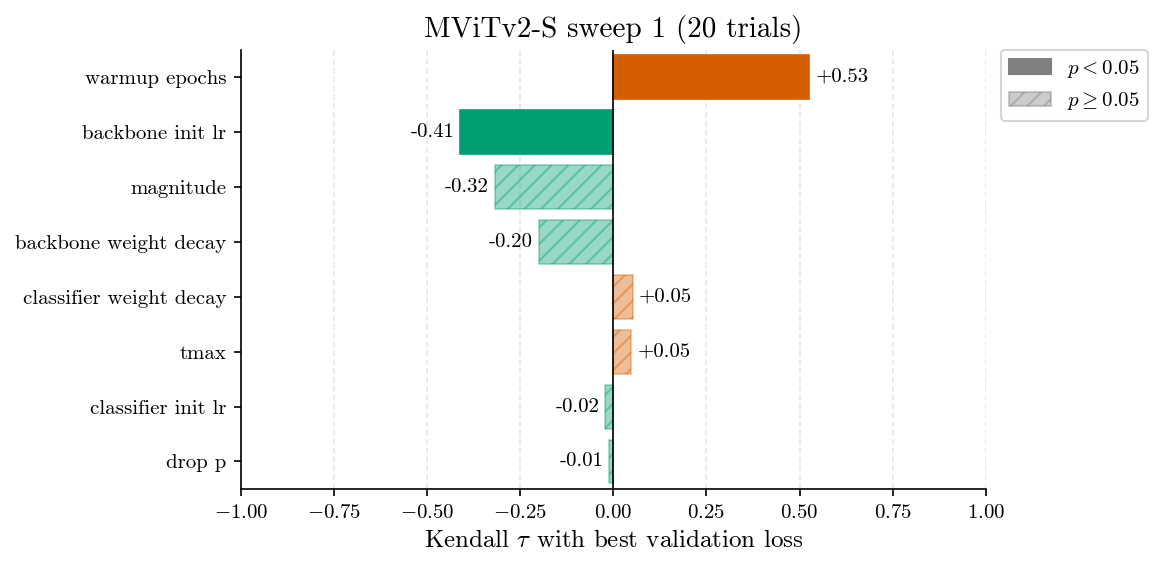

,tau,tau_p
param,,
warmup_epochs,0.526,0.006
backbone_init_lr,-0.411,0.011
magnitude,-0.318,0.060
backbone_weight_decay,-0.200,0.233
classifier_weight_decay,0.053,0.773
tmax,0.049,0.769
classifier_init_lr,-0.021,0.924
drop_p,-0.011,0.974


In [3]:
taus = kendall_taus(trials, tuned).sort_values('tau', key=np.abs, ascending=False)
fig, ax = plot_correlation_bars(
    list(taus.index),
    {sweep.label: taus['tau']},
    {sweep.label: taus['tau_p']},
    xlabel=r'Kendall $\tau$ with best validation loss',
    title=f'{sweep.label} ({len(trials)} trials)',
    figsize=(8, 4),
)
path = save_fig(fig, get_asset_path(f'param_tau_{sweep.label.replace(" ", "_")}', sweep.stub, project_name))
print(f'Saved: {path}')
plt.show()
taus.round(3)


Sweep 1 (2026-10-30): only `warmup_epochs` ($+0.53$, p = 0.006) and the backbone LR ($-0.41$,
p = 0.01) are significant, and they are confounded: the trials with 8 warmup epochs also had the
lowest backbone LRs (see the [findings](#Sweep-1-(510lhysg,-20-trials,-run-2026-10-30)) below).
`magnitude` leans the same way as the LR ($-0.32$, p = 0.06).


## Random-forest importance

Not in the thesis since 2026-10-30; a check on the $\tau$ chart.


In [4]:
importance = param_importance(trials, tuned)
importance['oob_permutation'] = oob_permutation_importance(trials, tuned)
importance.round(3)

,importance,importance_low,importance_high,tau,tau_p,oob_permutation
param,,,,,,
drop_p,0.236,0.060,0.458,-0.011,0.974,0.028
backbone_init_lr,0.218,0.058,0.386,-0.411,0.011,0.117
backbone_weight_decay,0.171,0.032,0.332,-0.200,0.233,-0.005
classifier_init_lr,0.127,0.014,0.316,-0.021,0.924,0.007
magnitude,0.080,0.020,0.212,-0.318,0.060,-0.006
tmax,0.076,0.007,0.207,0.049,0.769,-0.003
warmup_epochs,0.054,0.005,0.178,0.526,0.006,0.017
classifier_weight_decay,0.038,0.004,0.116,0.053,0.773,0.014


## Importance chart

Saved as `param_importance_<label>_<stub>.pdf` under `results/outputs/sweeping/`.


Saved: /home/luke/Code/SLR/src/results/outputs/sweeping/param_importance_MViTv2-S_sweep_1_asl100_cutoff_9_MViTv2_S_16x4_e_510lhysg_.pdf


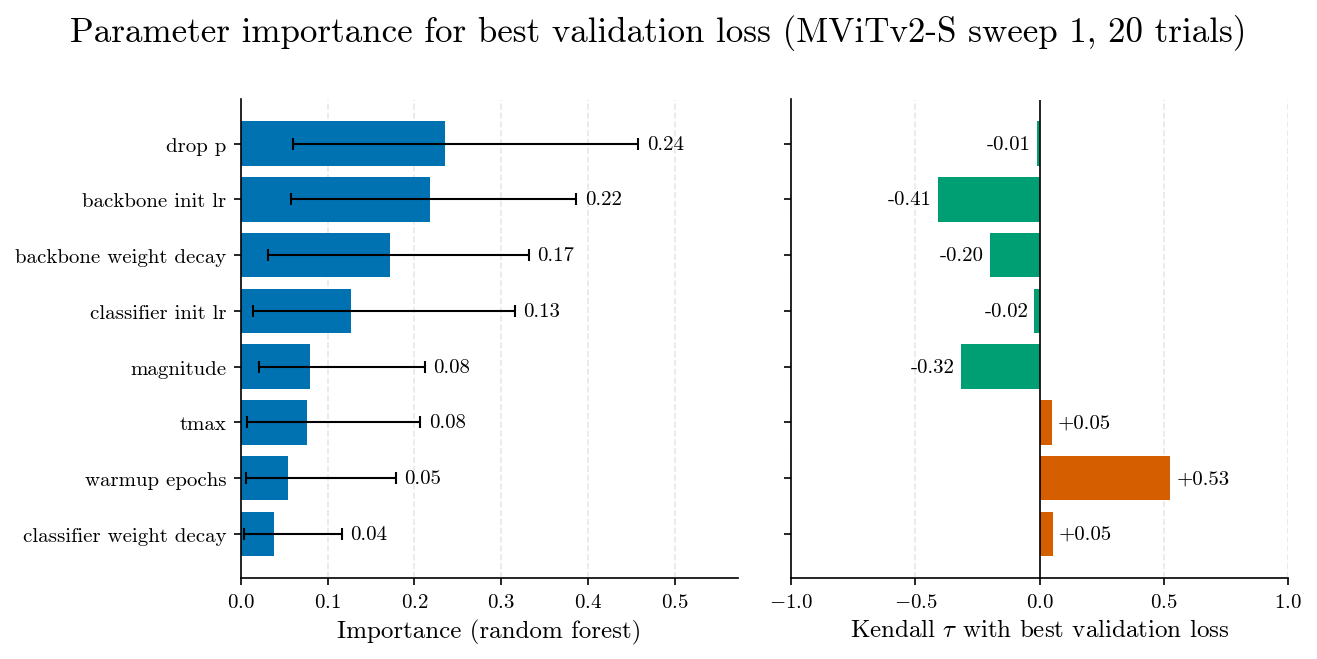

In [5]:
fig, axes = plot_param_importance(
    list(importance.index),
    importance['importance'],
    importance['tau'],
    importance_interval=(importance['importance_low'], importance['importance_high']),
    importance_label='Importance (random forest)',
    correlation_label=r'Kendall $\tau$ with best validation loss',
    title=f'Parameter importance for best validation loss ({sweep.label}, {len(trials)} trials)',
    figsize=(9, 4.5),
)
path = save_fig(fig, get_asset_path(f'param_importance_{sweep.label.replace(" ", "_")}', sweep.stub, project_name))
print(f'Saved: {path}')
plt.show()

## Stability: without the worst trial

The same table with the trial of highest best val loss left out. With ~20 trials, rankings that
change here rest on one trial and shouldn't be read into.

In [6]:
worst = int(np.argmax(trials['best_val_loss'].to_numpy()))
without_worst = trials.loc[trials.index != worst].reset_index(drop=True)
print(f'Left out: {trials.at[worst, "run_id"]} (best val loss {trials.at[worst, "best_val_loss"]:.3f})')
sensitivity = param_importance(without_worst, tuned)
sensitivity['oob_permutation'] = oob_permutation_importance(without_worst, tuned)
pd.DataFrame({
    'rank, all trials': importance['importance'].rank(ascending=False).astype(int),
    'rank, without worst': sensitivity['importance'].rank(ascending=False).astype(int),
    'importance, without worst': sensitivity['importance'],
    'oob permutation, without worst': sensitivity['oob_permutation'],
    'tau, without worst': sensitivity['tau'],
    'tau p, without worst': sensitivity['tau_p'],
}).loc[importance.index].round(3)

Left out: k8gfimyb (best val loss 0.956)


,"rank, all trials","rank, without worst","importance, without worst","oob permutation, without worst","tau, without worst","tau p, without worst"
param,,,,,,
drop_p,1,2,0.200,0.035,-0.111,0.534
backbone_init_lr,2,3,0.181,0.073,-0.345,0.041
backbone_weight_decay,3,5,0.077,-0.019,-0.111,0.534
classifier_init_lr,4,1,0.232,0.072,0.041,0.836
magnitude,5,6,0.068,0.007,-0.250,0.154
tmax,6,4,0.125,-0.014,0.127,0.459
warmup_epochs,7,8,0.054,0.016,0.464,0.019
classifier_weight_decay,8,7,0.064,0.011,0.064,0.730


## Sweep 1 (`510lhysg`, 20 trials, run 2026-10-30)

- **Only the backbone LR is robust.** It ranks 2nd-3rd by impurity importance, first by
  out-of-bag permutation importance (0.12 of the loss variance; tied with `classifier_init_lr` at
  0.07 without the worst trial), and is the only numeric parameter with a significant $\tau$
  ($-0.41$, p = 0.01; higher LR, lower loss), with or without the worst trial.
- **The rest of the impurity ranking is noise.** Every interval overlaps the others, and leaving
  out the worst trial (`best val loss 0.956`) moves `classifier_init_lr` from 4th to 1st, while
  `drop_p`'s 0.24 rests on that trial: its permutation importance is 0.03 and $\tau$ $-0.01$.
- **`warmup_epochs`** has the largest $\tau$ ($+0.53$, p = 0.006: the 5 trials with 8 warmup epochs
  did worse) but low impurity importance (0.05), partly the two-valued bias. Those 4 trials also
  had low backbone LRs (0.9e-4 to 2.4e-4) (the Bayesian search sampled them together), so the two effects can't be
  separated here.
- `magnitude` leans the same way as the backbone LR ($\tau$ $-0.32$, p = 0.06).

## Comparison across sweeps

$\tau$ per parameter for the MViTv2 sweeps the thesis reports, one colour per sweep, over the
union of their swept parameters; a gap means that sweep fixed the parameter. Rows are sorted by the
mean $|\tau|$ over the sweeps that swept it. A sweep with fewer than `min_trials` finished trials
is left out, so this is one rerun once sweep 2 finishes. Saved as
`param_tau_comparison_sweeps_<numbers>_MViTv2_S.pdf`.

**Sweep 0** is plotted over all 24 trials. Hyperband stopped 18 of them at epoch 15, so for those
best val loss is the loss within 15 epochs, and their $\tau$ largely measures how fast a trial
learns rather than where it ends up. The alternative, its 6 finished trials, has no power (with
n = 6, $p < 0.05$ needs $|\tau| \geq 0.73$) and is itself selected by Hyperband on epoch-15
performance, so it is in the table (`sweep 0, finished`) but not the chart.


MViTv2-S sweep 0: 24 finished trials, 0 diverged (left out)
MViTv2-S sweep 1: 20 finished trials, 0 diverged (left out)
MViTv2-S sweep 2: 1 finished trials, 0 diverged (left out)
Left out (too few finished trials): ['sweep 2']


Saved: /home/luke/Code/SLR/src/results/outputs/sweeping/param_tau_comparison_sweeps_0_1_MViTv2_S.pdf


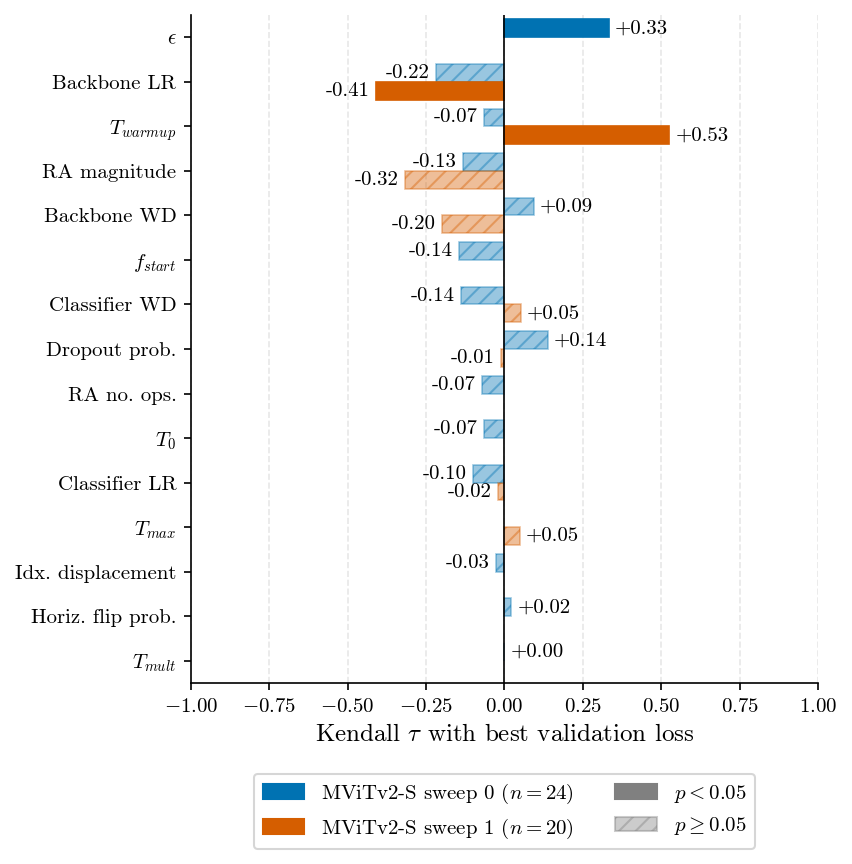

sweep 0 (n = 24)        sweep 1 (n = 20)         \
                                     tau  tau_p              tau  tau_p   
param                                                                     
eps                                0.333  0.023              NaN    NaN   
backbone_init_lr                  -0.217  0.145           -0.411  0.011   
warmup_epochs                     -0.066  0.687            0.526  0.006   
magnitude                         -0.132  0.391           -0.318  0.060   
backbone_weight_decay              0.094  0.539           -0.200  0.233   
start_factor                      -0.145  0.337              NaN    NaN   
classifier_weight_decay           -0.138  0.363            0.053  0.773   
drop_p                             0.138  0.363           -0.011  0.974   
num_ops                           -0.072  0.645              NaN    NaN   
t0                                -0.066  0.654              NaN    NaN   
classifier_init_lr                -0.101  0.507           -0.021  0.924   
tmax                                 NaN    NaN            0.049  0.769   
max_wobble                        -0.027  0.861              NaN    NaN   
hflip_p                            0.022  0.902              NaN    NaN   
tmult                              0.000  1.000              NaN    NaN   

                        sweep 0, finished (n = 6)         
                                              tau  tau_p  
param                                                     
eps                                         0.600  0.136  
backbone_init_lr                           -0.600  0.136  
warmup_epochs                               0.086  0.822  
magnitude                                  -0.545  0.150  
backbone_weight_decay                       0.333  0.469  
start_factor                                0.067  1.000  
classifier_weight_decay                    -0.067  1.000  
drop_p                                     -0.333  0.469  
num_ops                                    -0.072  0.845  
t0                                          0.067  1.000  
classifier_init_lr                          0.067  1.000  
tmax                                          NaN    NaN  
max_wobble                                 -0.414  0.251  
hflip_p                                    -0.200  0.719  
tmult                                      -0.115  0.770

In [7]:
compared = ['sweep 0', 'sweep 1', 'sweep 2']
# The names in the thesis's sweep tables (tab:sweep_0, tab:sweep_1).
thesis_labels = {
    'backbone_init_lr': 'Backbone LR',
    'classifier_init_lr': 'Classifier LR',
    'backbone_weight_decay': 'Backbone WD',
    'classifier_weight_decay': 'Classifier WD',
    'eps': r'$\epsilon$',
    'drop_p': 'Dropout prob.',
    'magnitude': 'RA magnitude',
    'num_ops': 'RA no. ops.',
    'hflip_p': 'Horiz. flip prob.',
    'max_wobble': 'Idx. displacement',
    'start_factor': r'$f_{start}$',
    'warmup_epochs': r'$T_{warmup}$',
    't0': r'$T_0$',
    'tmult': r'$T_{mult}$',
    'tmax': r'$T_{max}$',
}
min_trials = 15  # of 20 for sweep 2
hyperband_min_iter = 15  # sweep 0's early_terminate.min_iter

loaded = {name: load_sweep(sweeps[name]) for name in compared}
included = [name for name in compared if len(loaded[name][0]) >= min_trials]
print('Left out (too few finished trials):', [name for name in compared if name not in included])

s0 = sweeps['sweep 0']
s0_trials, s0_params = loaded['sweep 0']
s0_epochs: dict[str, dict[str, int]] = load_json(get_stash_path(s0.stub, base_name='epochs'))
s0_finished = s0_trials.loc[
    s0_trials['run_id'].map(lambda r: s0_epochs[r]['last_epoch'] > hyperband_min_iter)
].reset_index(drop=True)

tables = {f'{name} (n = {len(loaded[name][0])})': kendall_taus(*loaded[name]) for name in included}
comparison = pd.concat(tables, axis=1)
by_tau = comparison.xs('tau', axis=1, level=1)
comparison = comparison.loc[by_tau.abs().mean(axis=1).sort_values(ascending=False).index]
by_tau, by_p = comparison.xs('tau', axis=1, level=1), comparison.xs('tau_p', axis=1, level=1)

legend = {f'{sweeps[name].label} ($n = {len(loaded[name][0])}$)': name for name in included}
fig, ax = plot_correlation_bars(
    [thesis_labels[p] for p in comparison.index],
    {label: by_tau.iloc[:, i] for i, label in enumerate(legend)},
    {label: by_p.iloc[:, i] for i, label in enumerate(legend)},
    xlabel=r'Kendall $\tau$ with best validation loss',
    legend_loc='below',
    figsize=(5.9, 6),  # \linewidth (15 cm) in the thesis, so text keeps its point size
)
numbers = '_'.join(name.split()[1] for name in included)
path = save_fig(fig, get_asset_path(f'param_tau_comparison_sweeps_{numbers}', 'MViTv2_S', project_name))
print(f'Saved: {path}')
plt.show()

table = comparison.join(
    pd.concat({f'sweep 0, finished (n = {len(s0_finished)})': kendall_taus(s0_finished, s0_params)}, axis=1)
)
table.round(3)


### Sweeps 0 and 1 (run 2026-10-30; sweep 2 still running)

- **Only the backbone LR agrees across sweeps**: negative in both (higher LR, lower loss), $-0.22$
  (p = 0.15) in sweep 0 and $-0.41$ (p = 0.01) in sweep 1. Sweep 1's range (3e-5 to 6e-4) was the
  upper part of sweep 0's (1e-5 to 1e-3).
- **`warmup_epochs` doesn't replicate**: $+0.53$ (p = 0.006) in sweep 1, where it was 5 or 8 and the
  8s came with low backbone LRs, against $-0.07$ in sweep 0, where it was 0, 2, 5 or 8.
- **`eps`** is sweep 0's only significant $\tau$ ($+0.33$, p = 0.02: smaller eps, lower loss); sweep
  1 fixed it at 3e-6 on that basis.
- `t0` (sweep 0, `CosineAnnealingWarmRestarts` with `tmult`) and `tmax` (sweeps 1-2, one cosine
  cycle then held) are kept as separate rows, as they set different schedules.

Caption note (thesis §4.5, chosen 2026-10-30 to replace `fig:sweep_1_corr`): each bar is
computed within one sweep, over that sweep's own trials (they are not pooled), so a gap means that
sweep fixed the parameter. Each $\tau$ is relative to that sweep's search range (`tab:sweep_0`,
`tab:sweep_1`), so magnitudes are not directly comparable across sweeps (range restriction).
Hyperband stopped 18 of sweep 0's 24 trials at epoch 15, so for them $\tau$ measures the loss
reached within 15 epochs. The sweeps differ in implementation (sweep 2 is torchvision's MViTv2_S,
sweeps 0-1 PySlowFast's MViTv2_S_16x4) and split (sweep 2 uses the corrected `asl100`, sweeps 0-1
`asl100_cutoff_9`). $\tau$ looks at one parameter at a time, and the Bayesian search did not sample
them independently.
